# Predicting Diabetes Disease Progression: OLS, Ridge and Lasso with Feature Engineering

## 1. Project Objective
In this project I build regression models that predict how far a patient's diabetes will have progressed one year after their baseline measurements. In other words, I want to learn a function f: R^10 -> R so that ŷ = f(x) is a good estimate of the progression score y. The main question I'm trying to answer is: **how do feature engineering, model complexity and regularization change how well OLS, Ridge and Lasso predict disease progression?**

## 2. Dataset Description
The data is scikit-learn's `load_diabetes`. It has 442 patients, 10 baseline features and one continuous target. The features come already mean-centred and scaled.

| Feature | Description |
|---|---|
| age | Age of the individual |
| sex | Sex of the individual |
| bmi | Body Mass Index |
| bp | Average blood pressure |
| s1 | Total serum cholesterol |
| s2 | Low-density lipoproteins (LDL) |
| s3 | High-density lipoproteins (HDL) |
| s4 | Total cholesterol / HDL ratio |
| s5 | Log-transformed serum triglycerides level |
| s6 | Blood sugar level |

## Approach
First I explore the data. Then I answer the research questions using cross-validation on the training data, look at what powers and interaction terms do, and see how raising the polynomial degree changes things. At the very end I check the models on a held-out test set.

## 5. Training and Testing Strategy
I split the data once, 80% for training (353 rows) and 20% for testing (89 rows). Everything that involves choosing a model or tuning a setting, including the Ridge and Lasso penalties, uses only the training data and 5-fold cross-validation with the same folds for every model. The test set is only used at the end, to report how the models do on unseen data, and never to pick between them.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_score, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, StandardScaler
from sklearn.svm import SVR

# Single seed used everywhere for reproducibility
SEED = 42
np.random.seed(SEED)

# Load the dataset as a DataFrame (features + target)
diabetes = load_diabetes(as_frame=True)
X = diabetes.data
y = diabetes.target

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Section 5: split once. All model selection / tuning below uses ONLY the training part (via cross-validation);
# the test set is used a single time at the very end.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)   # same folds for every comparison
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])
X.head()

Features shape: (442, 10)
Target shape: (442,)
Train size: 353 | Test size: 89


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [ ]:
# Basic data checks
print("Missing values:", int(X.isna().sum().sum()) + int(y.isna().sum()))
print("Duplicate rows:", int(X.duplicated().sum()))
display(X.describe().round(3))
print("Target (disease progression after one year):")
display(y.describe().round(1))

# Note: the 10 features in this dataset are already mean-centred and scaled by scikit-learn,
# so their raw coefficients are on a comparable scale.

Missing values: 0
Duplicate rows: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136


Target (disease progression after one year):


,target
count,442.0
mean,152.1
std,77.1
min,25.0
25%,87.0
50%,140.5
75%,211.5
max,346.0


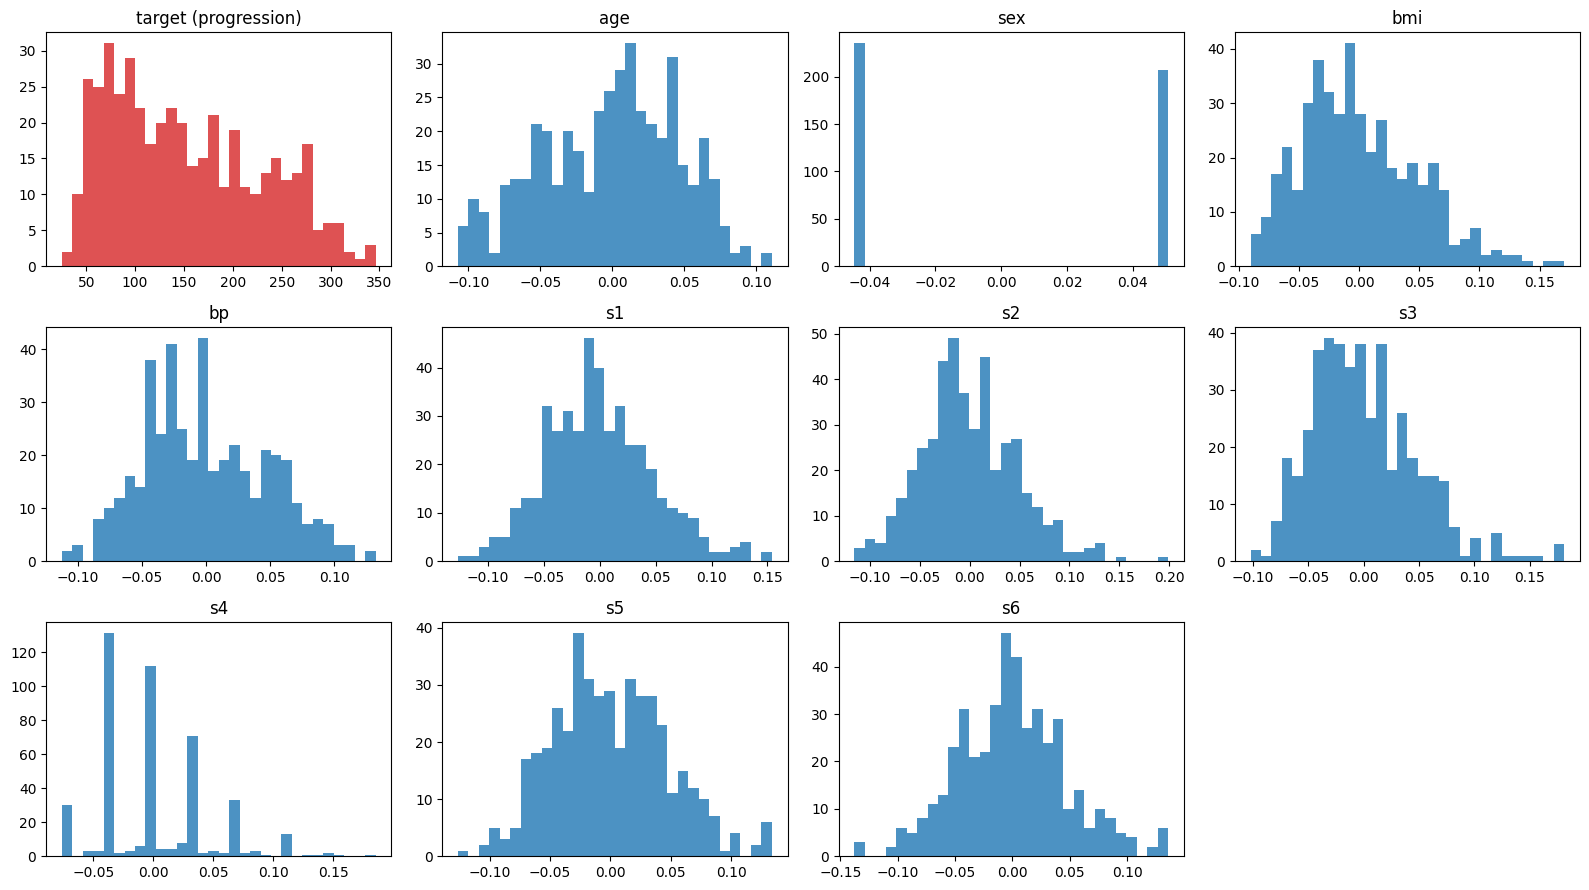

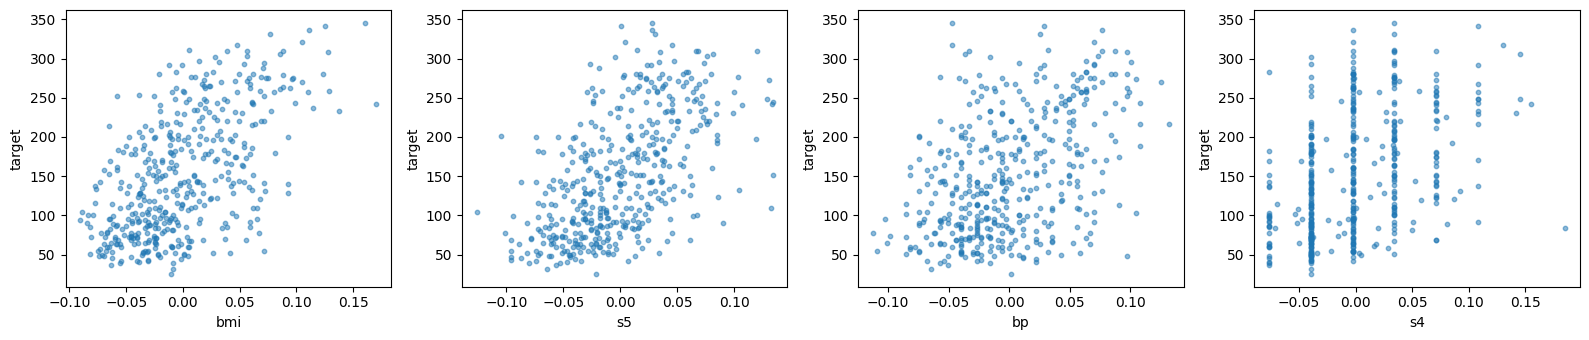

In [ ]:
# Exploratory data analysis: distributions of the target and the features
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
axes = axes.ravel()
axes[0].hist(y, bins=30, color="tab:red", alpha=0.8)
axes[0].set_title("target (progression)")
for ax, col in zip(axes[1:], X.columns):
    ax.hist(X[col], bins=30, alpha=0.8)
    ax.set_title(col)
for ax in axes[11:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Scatter of the four features most correlated with the target
top = X.corrwith(y).abs().nlargest(4).index
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, top):
    ax.scatter(X[col], y, s=10, alpha=0.5)
    ax.set_xlabel(col)
    ax.set_ylabel("target")
plt.tight_layout()
plt.show()

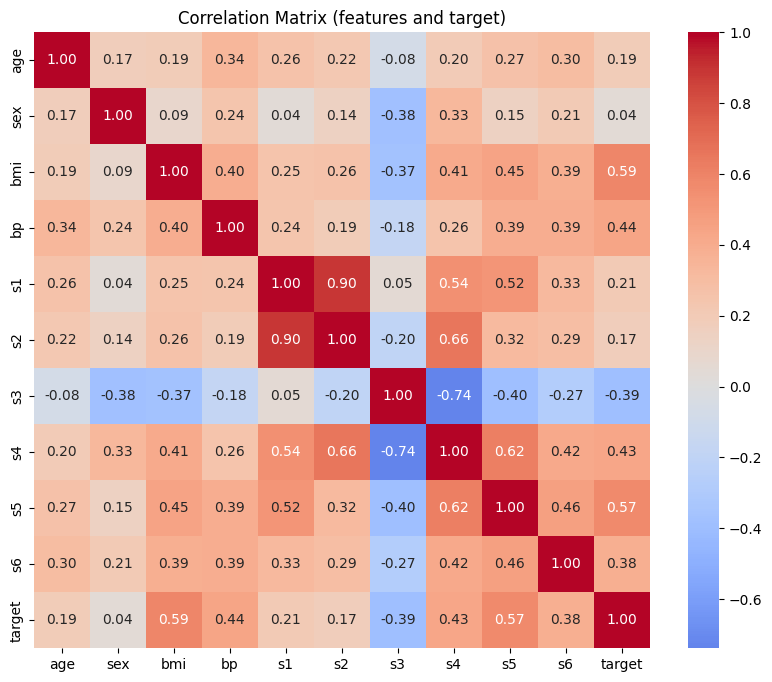

,target
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062
s3,-0.394789


In [ ]:
# Combine features and target, then compute the correlation matrix
df = X.copy()
df["target"] = y
corr = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix (features and target)")
plt.show()

# Correlation of each feature with the target
corr["target"].drop("target").sort_values(ascending=False)

#### Research Questions

1. Which baseline characteristics have the strongest statistical association with disease progression?

    Ans: BMI (+0.59) and s5 (triglycerides, +0.57) are clearly the strongest. Blood pressure (+0.44), s4 (+0.43), s3 (-0.39) and s6 (+0.38) come next with moderate associations.

    Direction: s3 (HDL, -0.39) is the only feature that is negatively correlated with progression, so higher HDL goes with less progression. Every other feature is positively correlated.

## 4. Modelling Strategy

### 4.1 Linear Regression (OLS)
OLS is the baseline. It picks the coefficients that minimise the sum of squared residuals, with no penalty. It's easy to read, but it can become unstable when predictors are correlated or when there are a lot of features.

In [ ]:
model = LinearRegression().fit(X_train, y_train)
print(f"Train R^2: {r2_score(y_train, model.predict(X_train)):.3f}")

# 5-fold cross-validation on the TRAINING data only
cv = cross_validate(LinearRegression(), X_train, y_train, cv=kf,
                    scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"))
print(f"5-fold CV R^2 : {cv['test_r2'].mean():.3f} (+/- {cv['test_r2'].std():.3f})")
print(f"5-fold CV RMSE: {-cv['test_neg_root_mean_squared_error'].mean():.2f}")
print(f"5-fold CV MAE : {-cv['test_neg_mean_absolute_error'].mean():.2f}")

# Coefficients (raw features are already on a comparable scale)
pd.Series(model.coef_, index=X.columns).sort_values()

Train R^2: 0.528
5-fold CV R^2 : 0.480 (+/- 0.041)
5-fold CV RMSE: 55.39
5-fold CV MAE : 45.05


,0
s1,-931.488846
sex,-241.964362
age,37.904021
s6,48.670657
s3,163.419983
s4,275.317902
bp,347.703844
s2,518.062277
bmi,542.428759
s5,736.198859


2. How well can a linear model explain the variation in the target?

    Ans: On the training data, OLS gets a 5-fold cross-validated R² of 0.480 (+/- 0.041), with a CV RMSE of about 55.4 and a CV MAE of about 45.0. So a linear model explains roughly half of the variation in disease progression. The other half could be noise, predictors we don't have, or non-linear effects, and R² alone can't tell us which. The test-set R² of the final model (0.454, see the final evaluation) is close to the CV estimate, so the CV number was a fair guide.

In [ ]:
# Variance inflation factor: how well each feature is predicted by the other features
# (VIF > 5-10 indicates strong multicollinearity)
vif = {}
for col in X.columns:
    r2 = LinearRegression().fit(X.drop(columns=col), X[col]).score(X.drop(columns=col), X[col])
    vif[col] = 1 / (1 - r2)
print("VIF per feature")
display(pd.Series(vif).sort_values(ascending=False).round(2))

VIF per feature


,0
s1,59.20
s2,39.19
s3,15.40
s5,10.08
s4,8.89
bmi,1.51
s6,1.48
bp,1.46
sex,1.28
age,1.22


### 4.2 Ridge Regression and 4.3 Lasso Regression
Ridge adds an ℓ2 penalty that pulls coefficients towards zero, which keeps the estimates steadier when predictors are correlated. Lasso uses an ℓ1 penalty instead, and that can push some coefficients all the way to zero, so it shrinks and selects features at the same time. For both, I choose the penalty strength by cross-validation on the training data. Features are standardised inside each pipeline so the penalty treats them all fairly.

In [ ]:
alphas = [10 ** a for a in range(-4, 3)]

models = {
    "OLS": LinearRegression(),
    "Ridge": RidgeCV(alphas=alphas),
    "Lasso": LassoCV(alphas=alphas, max_iter=100000, random_state=SEED),
}

# Same folds (kf, defined above) for every model; training data only
rows = []
for name, est in models.items():
    pipe = make_pipeline(StandardScaler(), est)
    cv = cross_validate(pipe, X_train, y_train, cv=kf,
                        scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"))
    rows.append({"model": name, "CV R2": cv["test_r2"].mean(), "R2 std": cv["test_r2"].std(),
                 "CV RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
                 "CV MAE": -cv["test_neg_mean_absolute_error"].mean()})

results = pd.DataFrame(rows).set_index("model").round(3)
display(results)

# Coefficients (standardised features) fitted on the training data
coefs = {}
for name, est in models.items():
    pipe = make_pipeline(StandardScaler(), est).fit(X_train, y_train)
    coefs[name] = pipe[-1].coef_
    if name != "OLS":
        print(f"{name}: selected alpha = {pipe[-1].alpha_}")
print("Coefficient table: OLS vs Ridge vs Lasso (standardised features, fitted on the training data)")
display(pd.DataFrame(coefs, index=X.columns).round(1))

,CV R2,R2 std,CV RMSE,CV MAE
model,,,,
OLS,0.48,0.041,55.395,45.048
Ridge,0.48,0.041,55.419,45.119
Lasso,0.48,0.040,55.394,45.180


Ridge: selected alpha = 1.0
Lasso: selected alpha = 1.0
Coefficient table: OLS vs Ridge vs Lasso (standardised features, fitted on the training data)


,OLS,Ridge,Lasso
age,1.8,1.8,0.7
sex,-11.5,-11.4,-9.3
bmi,25.6,25.7,26.2
bp,16.8,16.7,15.7
s1,-44.4,-34.7,-8.2
s2,24.6,17.1,-0.0
s3,7.7,3.4,-9.0
s4,13.1,11.8,3.4
s5,35.2,31.4,22.6
s6,2.4,2.5,2.1


3. Does regularization improve generalization when predictors are correlated?

    Ans: Not for prediction accuracy. With the same 5-fold CV on the training data, OLS, Ridge and Lasso all reach a CV R² of about 0.48 and a CV RMSE of about 55.4 (OLS 55.395, Ridge 55.419, Lasso 55.394). The differences are tiny compared with the fold-to-fold spread of about 0.04. With only 10 predictors and 353 training rows, OLS doesn't have much variance for regularization to remove.

    Where regularization does help is stability, and the VIF values show why: s1 (59.2), s2 (39.2), s3 (15.4), s5 (10.1) and s4 (8.9) are strongly collinear, while the other features are all below 1.6. The unstable OLS coefficients get shrunk: s1 goes from -44.4 (OLS) to -34.7 (Ridge) to -8.2 (Lasso), s2 from 24.6 to 17.1 to 0.0, and s5 from 35.2 to 31.4 to 22.6. Lasso also flips s3 from +7.7 to -9.0. That is a sign Lasso is arbitrarily picking one representative from a group of correlated features rather than finding a true negative effect. The less collinear features (bmi, bp, sex, s6) barely change.

In [ ]:
# Same folds (kf) as the regularization comparison; training data only
nl_models = {
    "OLS (baseline)": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2, random_state=SEED),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(C=100, gamma=0.01)),
}

rows = []
for name, est in nl_models.items():
    cv = cross_validate(est, X_train, y_train, cv=kf,
                        scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"))
    rows.append({"model": name, "CV R2": cv["test_r2"].mean(), "R2 std": cv["test_r2"].std(),
                 "CV RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
                 "CV MAE": -cv["test_neg_mean_absolute_error"].mean()})

print("Linear vs nonlinear models (5-fold CV on training data, same folds)")
display(pd.DataFrame(rows).set_index("model").round(3))

Linear vs nonlinear models (5-fold CV on training data, same folds)


,CV R2,R2 std,CV RMSE,CV MAE
model,,,,
OLS (baseline),0.480,0.041,55.395,45.048
Random Forest,0.432,0.068,57.793,47.591
Gradient Boosting,0.423,0.035,58.425,47.582
SVR (RBF),0.475,0.058,55.591,45.185


4. Do nonlinear models capture relationships that a linear model cannot?

    Ans: No, we don't see any evidence of that here. Under the same 5-fold CV on the training data, SVR with an RBF kernel (R² 0.475) is tied with OLS (0.480), while Random Forest (0.432) and Gradient Boosting (0.423) are a bit lower, by about 0.05 to 0.06. The polynomial models in section 4.4 tell the same story: adding non-linear terms never beat the plain linear fit.

    That suggests any non-linear structure is small compared with the noise, and a linear model does the job. The tree ensembles probably lose a little because 353 training rows is not much to learn from. I didn't tune the nonlinear models, so this can't fully rule out small non-linear effects.

In [ ]:
# Sensitivity of the PERFORMANCE conclusion: repeated CV (5 folds x 5 repeats) on the training data
rkf = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)
all_models = {
    "OLS": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(alphas=alphas, max_iter=100000, random_state=SEED)),
    "Random Forest": nl_models["Random Forest"],
    "Gradient Boosting": nl_models["Gradient Boosting"],
    "SVR (RBF)": nl_models["SVR (RBF)"],
}
rows = []
for name, est in all_models.items():
    r2 = cross_val_score(est, X_train, y_train, cv=rkf, scoring="r2")
    rows.append({"model": name, "CV R2": r2.mean(), "R2 std": r2.std()})
print("Repeated 5x5 CV across all models (training data)")
display(pd.DataFrame(rows).set_index("model").round(3))

Repeated 5x5 CV across all models (training data)


,CV R2,R2 std
model,,
OLS,0.479,0.081
Ridge,0.476,0.079
Lasso,0.475,0.077
Random Forest,0.425,0.106
Gradient Boosting,0.410,0.105
SVR (RBF),0.474,0.083


5. How sensitive are the conclusions to the choice of model?

    Ans: The conclusion about performance holds up well. In the repeated 5x5 CV, OLS (0.479), Ridge (0.476), Lasso (0.475) and SVR (0.474) are essentially identical, and Random Forest (0.425) and Gradient Boosting (0.410) are lower and more variable (std about 0.105 vs about 0.08). No model gets meaningfully above 0.48, so whichever model you pick, the message is the same: about half of the variation is explained.

    Conclusions about individual coefficients are more sensitive, but only for the correlated predictors. Between OLS, Ridge and Lasso, s1, s2, s3 and s5 change a lot (for example s2 goes 24.6, 17.1, 0.0 and s3 even changes sign under Lasso), so anything we say about those features depends on the model. BMI and blood pressure keep similar coefficients in all three. The engineered-feature results are also model-dependent: OLS falls apart there while Lasso holds up.

6. Which model provides the best balance between predictive accuracy and interpretability?

    Ans: Ridge regression on the original 10 features. In the 5-fold CV on the training data, accuracy is basically tied across OLS, Ridge, Lasso and SVR (CV R² about 0.48, RMSE about 55.4 to 55.6), while Random Forest (0.432) and Gradient Boosting (0.423) are lower. Ridge also had the best CV R² of all twelve configurations compared at the end (0.481), which is why the final evaluation selects it.

    Interpretability separates the models. Linear models give one coefficient per feature, with a sign and size you can read directly (BMI and s5 push progression up, blood pressure too). Random Forest, Gradient Boosting and SVR don't give that, they need extra tools to explain, and they don't buy any accuracy here.

    Among the linear models I prefer Ridge. It matches OLS on accuracy but shrinks the unstable coefficients of the correlated predictors s1, s2 and s3 (see question 3). Lasso is a reasonable alternative if you want a sparser model, but with this group of correlated features it picks one of them somewhat arbitrarily (it zeroes s2 and flips the sign of s3), so its individual coefficients are harder to trust. Plain OLS is fine too if you're not going to interpret the correlated lipid features one by one.

#### Feature-Engineered Regression

Here I add powers (x², x³) and pairwise interaction terms (xᵢxⱼ) to the features, then fit and compare OLS, Ridge and Lasso on the expanded set. I look at three things: (a) how the engineered features change performance, (b) how raising the polynomial degree affects performance and overfitting (train vs CV R²), and (c) which coefficients each method keeps. Every model uses the same folds (`kf`), and features are standardised inside each pipeline so the penalties treat them fairly.

In [ ]:
from itertools import combinations

# Engineered feature set: original + squares + cubes + pairwise interactions (10 + 10 + 10 + 45 = 75)
def add_features(df):
    out = df.copy()
    for c in df.columns:
        out[f"{c}^2"] = df[c] ** 2
        out[f"{c}^3"] = df[c] ** 3
    for a, b in combinations(df.columns, 2):
        out[f"{a}*{b}"] = df[a] * df[b]
    return out

# Row-wise transformation (no target, no fitted statistics), so it is safe to apply to train and test alike
X_fe = add_features(X)
X_fe_train = X_fe.loc[X_train.index]
print("Engineered feature matrix:", X_fe.shape)

# Wider penalty grids than in the original-feature comparison, since there are many more (and correlated) features
ridge_alphas = np.logspace(-1, 4, 30)
lasso_alphas = np.logspace(-2, 2, 30)

def make_models():
    return {
        "OLS": LinearRegression(),
        "Ridge": RidgeCV(alphas=ridge_alphas),
        "Lasso": LassoCV(alphas=lasso_alphas, max_iter=100000, random_state=SEED),
    }

def evaluate(Xm, label):
    """5-fold CV (same folds, kf) on the training rows; Xm must be built from the training data only."""
    rows = []
    for name, est in make_models().items():
        cv = cross_validate(make_pipeline(StandardScaler(), est), Xm, y_train, cv=kf,
                            scoring=("r2", "neg_mean_absolute_error"), return_train_score=True)
        rows.append({"features": label, "model": name, "n_features": Xm.shape[1],
                     "train R2": cv["train_r2"].mean(), "CV R2": cv["test_r2"].mean(),
                     "CV R2 std": cv["test_r2"].std(), "CV MAE": -cv["test_neg_mean_absolute_error"].mean(),
                     "overfit gap": cv["train_r2"].mean() - cv["test_r2"].mean()})   # train R2 minus CV R2
    return rows

rows = evaluate(X_train, "original") + evaluate(X_fe_train, "squares+cubes+interactions")
print("Original vs engineered features (5-fold CV on training data)")
display(pd.DataFrame(rows).set_index(["features", "model"]).round(3))

Engineered feature matrix: (442, 75)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 312.59569157729857, tolerance: 131.5309721238938
  model = cd_fast.enet_coordinate_descent_gram(


Original vs engineered features (5-fold CV on training data)


n_features  train R2  CV R2  CV R2 std  \
features                   model                                           
original                   OLS            10     0.531  0.480      0.041   
                           Ridge          10     0.526  0.481      0.039   
                           Lasso          10     0.524  0.477      0.036   
squares+cubes+interactions OLS            75     0.647  0.293      0.095   
                           Ridge          75     0.568  0.442      0.053   
                           Lasso          75     0.545  0.475      0.044   

                                  CV MAE  overfit gap  
features                   model                       
original                   OLS    45.048        0.050  
                           Ridge  45.069        0.045  
                           Lasso  45.334        0.047  
squares+cubes+interactions OLS    50.662        0.354  
                           Ridge  46.555        0.126  
                           Lasso  45.713        0.070

In [ ]:
# Coefficients selected by each method on the engineered feature set (fitted on the training data)
fitted = {}
for name, est in make_models().items():
    fitted[name] = make_pipeline(StandardScaler(), est).fit(X_fe_train, y_train)
coef_fe = pd.DataFrame({name: p[-1].coef_ for name, p in fitted.items()}, index=X_fe.columns)

print("Chosen penalties: Ridge alpha =", round(fitted["Ridge"][-1].alpha_, 2),
      "| Lasso alpha =", round(fitted["Lasso"][-1].alpha_, 3))
print("Non-zero coefficients:", (coef_fe.abs() > 1e-8).sum().to_dict(), "of", X_fe.shape[1])
print("Largest absolute coefficient:", coef_fe.abs().max().round(1).to_dict())

print("\nFeatures kept by Lasso (sorted by |coefficient|), with the same feature under OLS and Ridge")
kept = coef_fe[coef_fe["Lasso"].abs() > 1e-8].sort_values("Lasso", key=abs, ascending=False)
display(kept.round(1))

print("Top 10 features by |coefficient| for each method")
display(pd.DataFrame({n: coef_fe[n].abs().sort_values(ascending=False).head(10).index.tolist()
                      for n in coef_fe.columns}))

Chosen penalties: Ridge alpha = 126.9 | Lasso alpha = 1.61
Non-zero coefficients: {'OLS': 75, 'Ridge': 75, 'Lasso': 27} of 75
Largest absolute coefficient: {'OLS': 176.2, 'Ridge': 15.0, 'Lasso': 26.3}

Features kept by Lasso (sorted by |coefficient|), with the same feature under OLS and Ridge


,OLS,Ridge,Lasso
s5,37.1,15.0,26.3
bmi,15.8,13.7,18.5
s3,-18.4,-8.8,-13.3
bp,9.9,9.2,10.6
sex^2,-5.1,-3.2,-8.2
s5^3,-73.8,-1.0,-7.7
bmi^3,9.5,7.8,6.9
age*sex,2.7,4.4,5.5
bp^3,10.5,7.2,5.1
bmi*bp,12.4,4.8,4.7


Top 10 features by |coefficient| for each method


,OLS,Ridge,Lasso
0,s1*s2,s5,s5
1,s1*s5,bmi,bmi
2,s2*s5,bp,s3
3,s2^2,s3,bp
4,s4^2,bmi^3,sex^2
5,s5^2,bp^3,s5^3
6,s3*s4,s4,bmi^3
7,s5^3,bmi*bp,age*sex
8,s1*s4,s2^3,bp^3
9,s3*s5,age*s2,bmi*bp


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.147e+02, tolerance: 1.381e+02
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.610e+02, tolerance: 1.381e+02
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.941e+02, tolerance: 1.401e

Effect of polynomial degree (5-fold CV on training data)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.726e+02, tolerance: 1.373e+02
  model = cd_fast.enet_coordinate_descent(


n_features  train R2     CV R2  CV R2 std    CV MAE  \
features model                                                        
degree 1 OLS            10     0.531     0.480      0.041    45.048   
         Ridge          10     0.526     0.481      0.039    45.069   
         Lasso          10     0.524     0.477      0.036    45.334   
degree 2 OLS            65     0.626     0.339      0.070    49.629   
         Ridge          65     0.559     0.447      0.052    46.808   
         Lasso          65     0.524     0.460      0.033    46.523   
degree 3 OLS           285     0.980 -1279.029   1488.828  1066.015   
         Ridge         285     0.580     0.403      0.030    48.991   
         Lasso         285     0.527     0.442      0.033    47.285   

                overfit gap  
features model               
degree 1 OLS          0.050  
         Ridge        0.045  
         Lasso        0.047  
degree 2 OLS          0.287  
         Ridge        0.113  
         Lasso        0.064  
degree 3 OLS       1280.009  
         Ridge        0.177  
         Lasso        0.085

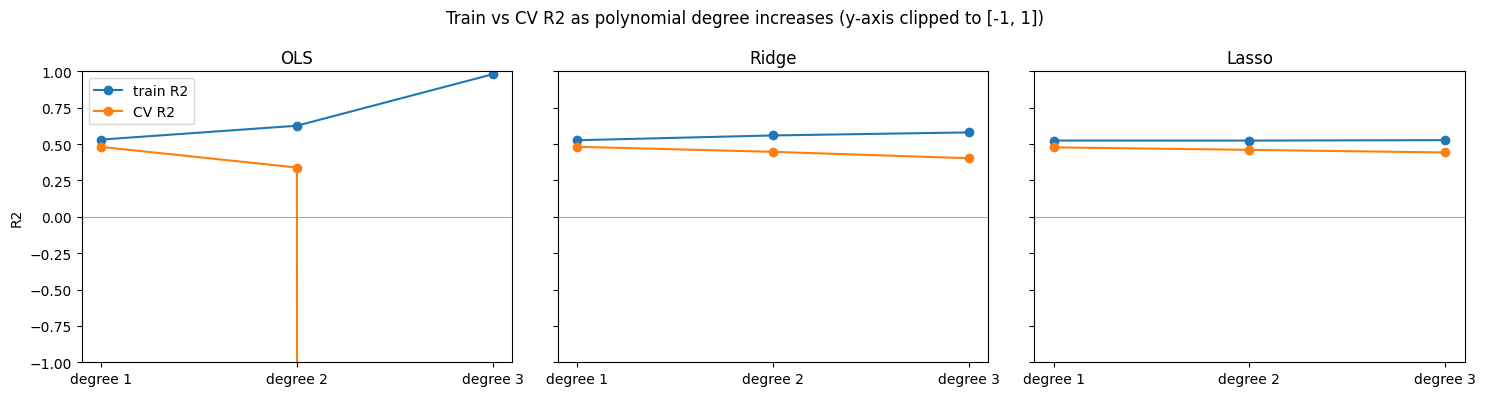

In [ ]:
# Effect of increasing polynomial degree (all powers and interactions up to the given degree), training data only
rows = []
for degree in [1, 2, 3]:
    Xp = pd.DataFrame(PolynomialFeatures(degree, include_bias=False).fit_transform(X_train))
    rows += evaluate(Xp, f"degree {degree}")
deg_results = pd.DataFrame(rows)
print("Effect of polynomial degree (5-fold CV on training data)")
display(deg_results.set_index(["features", "model"]).round(3))

# Train vs CV R2 by degree for each model
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, g) in zip(axes, deg_results.groupby("model", sort=False)):
    ax.plot(g["features"], g["train R2"], marker="o", label="train R2")
    ax.plot(g["features"], g["CV R2"], marker="o", label="CV R2")
    ax.set_title(name)
    ax.set_ylim(-1, 1)
    ax.axhline(0, color="grey", lw=0.5)
axes[0].set_ylabel("R2")
axes[0].legend()
plt.suptitle("Train vs CV R2 as polynomial degree increases (y-axis clipped to [-1, 1])")
plt.tight_layout()
plt.show()

**Note:** R² only has to stay between 0 and 1 on the data the model was fitted to. On held-out data (CV R²) it can go negative, and a negative value means the model does worse than just predicting the average of the target. That's what happens with degree-3 OLS here. With 285 features and only about 350 training rows per fold, it nearly memorises the training data (train R² = 0.88), but its predictions on unseen rows are way off. That gives a very negative CV R² with a large spread across folds. Ridge and Lasso avoid this by shrinking the coefficients.

#### 4.4 Answer: feature engineering, polynomial degree and regularization

**Feature engineering.** Adding squares, cubes and interactions (75 features) did not beat the original 10 features. On the original features the CV R² is 0.480 (OLS), 0.481 (Ridge) and 0.477 (Lasso). On the engineered set it drops to 0.293 (OLS) and 0.442 (Ridge). Only Lasso stays level, at 0.475.

**Polynomial degree and overfitting.** As the degree goes from 1 to 2 to 3, OLS fits the training data better and better (train R² 0.531, 0.626, 0.980) while its CV R² collapses (0.480, 0.339, then -1279, which is far worse than predicting the mean). Its train-minus-CV gap grows from 0.050 to 0.287 to over 1000. Ridge degrades gently (CV R² 0.481, 0.447, 0.403; gap 0.045, 0.113, 0.177) and Lasso degrades least (0.477, 0.460, 0.442; gap 0.047, 0.064, 0.085). The more features there are, the more regularization matters, and the stronger penalty of Lasso helps most.

**Coefficients.** On the 75 engineered features OLS keeps all of them, with some very large values (largest |coefficient| 176.2). Its biggest ones are interactions of the highly collinear lipid features (s1*s2, s1*s5, s2*s5), which are unstable. Ridge shrinks everything (largest 15.0) but keeps all 75. Lasso keeps only 27 of the 75. Under both Ridge and Lasso the strongest coefficients are the original main effects s5, bmi, bp and s3. Lasso also keeps a few non-linear terms (sex², s5³, bmi³, age*sex), but they are smaller than the main effects. So most of the signal is linear in s5, bmi, bp and s3.

### Final evaluation on the held-out test set (Section 5)
Every configuration below was chosen and tuned using the training data only. The table covers each feature set (original, engineered x²/x³/xᵢxⱼ, polynomial degree 2 and degree 3) with each model (OLS, Ridge, Lasso). It shows the 5-fold CV R² on the training data next to the test-set R², RMSE and MAE. The final model is the one with the best **CV** R², so the test set has no say in which model is picked.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 312.59569157729857, tolerance: 131.5309721238938
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.147e+02, tolerance: 1.381e+02
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.610e+02, tolerance: 1.381e+02
  model = cd_fast.enet_coordinate_descent(
/u

CV R2 (train)  test R2  test RMSE  test MAE
features                  model                                             
original                  OLS            0.480    0.453     53.853    42.794
                          Ridge          0.481    0.454     53.773    42.813
                          Lasso          0.477    0.471     52.923    42.787
engineered (x2, x3, xixj) OLS            0.293    0.411     55.840    44.901
                          Ridge          0.442    0.472     52.886    43.283
                          Lasso          0.475    0.518     50.543    40.635
degree 2                  OLS            0.339    0.416     55.642    43.582
                          Ridge          0.447    0.491     51.912    42.111
                          Lasso          0.460    0.516     50.626    41.196
degree 3                  OLS        -1279.029  -14.561    287.134   164.854
                          Ridge          0.403    0.414     55.713    46.011
                          Lasso          0.442    0.479     52.520    43.532

Final model chosen by CV R2: ('original', 'Ridge')


,,CV R2 (train),test R2,test RMSE,test MAE
features,model,,,,
original,Ridge,0.481,0.454,53.773,42.813


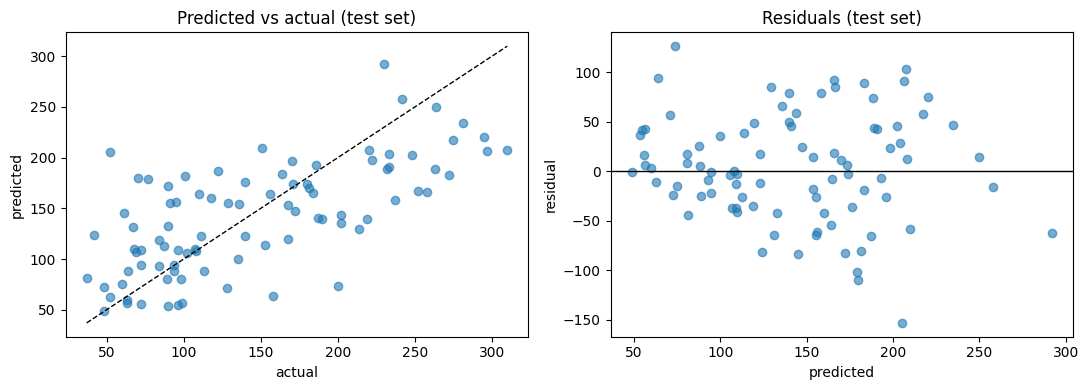

In [ ]:
# Feature sets compared in the final evaluation; each is applied inside the pipeline so nothing leaks from the test set
feature_sets = {
    "original": FunctionTransformer(),
    "engineered (x2, x3, xixj)": FunctionTransformer(add_features),
    "degree 2": PolynomialFeatures(2, include_bias=False),
    "degree 3": PolynomialFeatures(3, include_bias=False),
}

rows, fitted_final = [], {}
for fs_name, fs in feature_sets.items():
    for m_name, est in make_models().items():
        pipe = make_pipeline(fs, StandardScaler(), est)
        cv_r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")    # used for model selection (training data only)
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)                                             # test set: reporting only, never for selection
        rows.append({"features": fs_name, "model": m_name,
                     "CV R2 (train)": cv_r2.mean(),
                     "test R2": r2_score(y_test, pred),
                     "test RMSE": mean_squared_error(y_test, pred) ** 0.5,
                     "test MAE": mean_absolute_error(y_test, pred)})
        fitted_final[(fs_name, m_name)] = (pipe, pred)

final = pd.DataFrame(rows).set_index(["features", "model"])
display(final.round(3))

# Final model = best CV R2 on the training data (not best test R2)
best = final["CV R2 (train)"].idxmax()
print("Final model chosen by CV R2:", best)
display(final.loc[[best]].round(3))

# Predicted vs actual and residuals for the chosen model
pred = fitted_final[best][1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, pred, alpha=0.6)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "k--", lw=1)                  # perfect-prediction line
axes[0].set_xlabel("actual")
axes[0].set_ylabel("predicted")
axes[0].set_title("Predicted vs actual (test set)")
axes[1].scatter(pred, y_test - pred, alpha=0.6)
axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("predicted")
axes[1].set_ylabel("residual")
axes[1].set_title("Residuals (test set)")
plt.tight_layout()
plt.show()

#### Final evaluation and conclusion

**Final model.** Selecting by CV R² on the training data picks Ridge on the original features (CV R² 0.481). On the test set it gets R² 0.454, RMSE 53.8 and MAE 42.8. That is close to the CV estimate, so cross-validation gave a fair picture of how the model generalizes.

**A note on the other test scores.** Lasso on the engineered features (test R² 0.518) and on degree 2 (0.516) scored higher on the test set than the chosen model. Their CV R² was not higher (0.475 and 0.460), and the test set has only 89 rows, so a gap of about 0.06 can easily be noise. Switching to them because of the test result would mean using the test set for selection, so I keep the CV choice. Degree-3 OLS has a test R² of -14.6, which confirms the overfitting seen in cross-validation.

**Central question: how do feature engineering, model complexity and regularization affect OLS, Ridge and Lasso?**
- Feature engineering did not improve prediction. The best CV R² stays at about 0.48, reached by the original features.
- Increasing complexity hurts OLS badly (its CV R² falls from 0.480 to 0.339 to -1279 as the degree goes from 1 to 3). Ridge degrades gently, and Lasso is the most robust.
- Regularization doesn't improve accuracy when the model is small (10 features) but becomes essential as features multiply. It also stabilizes the coefficients of the correlated lipid features, and Lasso additionally selects features (27 of 75).
- Overall, the signal in this dataset is mostly linear and mainly carried by s5, bmi, bp and s3, and about half of the variation in progression remains unexplained by any model I tried.